# Complex analysis 6: The residue theorem

*Learning path: complex analysis, part 6 of 8.* [Index](README.md) · Previous: [Taylor and Laurent series](05-taylor-and-laurent.ipynb) · Next: [Real integrals](07-real-integrals.ipynb)

How many roots does $z^5 + 3z + 1$ have inside the unit circle? You could solve the quintic numerically, but there is
a way to count them without finding a single one: one integral around the circle. And $1 + \tfrac14 + \tfrac19 +
\tfrac1{16} + \cdots = \pi^2/6$, Euler's famous sum, follows from the same idea. Both are consequences of the **residue
theorem**, which turns a contour integral into a finite sum of numbers read off at the singularities. It is the most
used result of complex analysis in physics and engineering.

**Who this is for.** You have done [lesson 5](05-taylor-and-laurent.ipynb) and know what a residue is.

**What you will be able to do afterwards:**

1. state the residue theorem and use it to evaluate contour integrals;
2. compute residues at simple and higher-order poles by formula, with `residue` and with `poles`;
3. count zeros and poles inside a curve with the argument principle;
4. sum series like $\sum 1/k^2$ with residues.

Plan about an hour.

## 1. The residue theorem

Let $f$ be analytic inside and on a closed loop $\gamma$, traversed counterclockwise, except at finitely many points
$a_1, \ldots, a_n$ inside. Then

$$\oint_\gamma f\,dz = 2\pi i\sum_{k} \operatorname{Res}(f, a_k).$$

Why: by Cauchy's theorem the loop can be shrunk to small circles around each $a_k$ (lesson 4), and on each one only the
$c_{-1}$ term of the Laurent series survives (lesson 5). Test it on $e^z/(z^2 + 1)$, with simple poles at $\pm i$,
around the circle $|z| = 2$:

In [1]:
poles(exp(z)/(z^2 + 1), z)
cint(exp(z)/(z^2 + 1), z, 2*exp(i*t), t, 0, 2*pi)
eval(2*pi*i*(exp(i)/(2*i) + exp(-i)/(-2*i)))

[-i, 1, exp(-i)*i/2;
  i, 1, -exp(i)*i/2]

> Poles: one row [pole, order, residue] for each zero of the denominator that the numerator does not cancel.

5.28711812816*i

> Contour integral of f dz along z = 2*exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

5.287118128162912*i

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The numeric integral and $2\pi i$ times the sum of the residues agree. That sum is $2\pi i\sin 1$, since
$(e^i - e^{-i})/2i = \sin 1$.

**Try this.** What is the integral of the same function around $|z - i| = 1$, which encloses only one pole? Predict it,
then check with `cint`.

## 2. Computing residues

`residue(f, z, a)` does the work, but the formulas are short and worth knowing.

* **Simple pole**, $f = g/h$ with $h(a) = 0$, $h'(a) \ne 0$: $\operatorname{Res}(f, a) = g(a)/h'(a)$.
* **Pole of order $m$:** $\operatorname{Res}(f, a) = \dfrac{1}{(m - 1)!}\lim_{z \to a}\dfrac{d^{m-1}}{dz^{m-1}}
  \left[(z - a)^m f(z)\right]$.

For $e^z/(z^2 + 1)$ at $i$, $g/h' = e^z/(2z)$ at $z = i$:

In [2]:
subs(exp(z)/diff(z^2 + 1, z), z, i)
residue(exp(z)/(z^2 + 1), z, i)

-exp(i)*i/2

> `subs`: Replaces the variable x by a value.

-exp(i)*i/2

> Residue of f at z = i: a simple pole: the residue is the limit of (z − a) f as z → a.

$e^i/(2i) = -ie^i/2$. For $1/(z^2(z - 1))$, a double pole at 0: $(z - 0)^2 f = 1/(z - 1)$, whose derivative at 0 is
$-1/(z - 1)^2 = -1$. At the simple pole $z = 1$ the residue is $1/z^2 = 1$:

In [3]:
residue(1/(z^2*(z - 1)), z, 0)
residue(1/(z^2*(z - 1)), z, 1)
cint(1/(z^2*(z - 1)), z, 2*exp(i*t), t, 0, 2*pi)

-1

> Residue of f at z = 0: a pole of order 2: the residue is the coefficient of 1/(z − a) in the Laurent series, equivalently the derivative of order 1 of (z − a)^2 f at a, divided by 1!.

1

> Residue of f at z = 1: a simple pole: the residue is the limit of (z − a) f as z → a.

0.0

> Contour integral of f dz along z = 2*exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

Around $|z| = 2$ both poles are inside, and $-1 + 1 = 0$. That is no accident: for large $|z|$ this $f$ behaves like
$1/z^3$, and by the ML estimate the integral over a huge circle tends to 0, so the residues must add up to zero.

**Try this.** Compute the residue of $z/(z - 1)^3$ at 1 with the order-3 formula, and check with `residue`.

## 3. Counting zeros: the argument principle

If $f$ has a zero of order $m$ at $a$, then $f'/f = m/(z - a) + (\text{analytic})$ near $a$: a simple pole with residue
$m$. At a pole of order $m$ the residue of $f'/f$ is $-m$. So for a loop on which $f$ has no zeros or poles,

$$\frac{1}{2\pi i}\oint_\gamma \frac{f'}{f}\,dz = Z - P,$$

the number of zeros minus the number of poles inside, counted with order. This is the **argument principle**: the
integral of $f'/f = (\log f)'$ measures how many times $f(z)$ winds around 0 as $z$ goes round $\gamma$, which is exactly
what the colors of a domain coloring show. Count the zeros of $z^5 + 3z + 1$:

In [4]:
cint(diff(z^5 + 3*z + 1, z)/(z^5 + 3*z + 1), z, exp(i*t), t, 0, 2*pi)
cint(diff(z^5 + 3*z + 1, z)/(z^5 + 3*z + 1), z, 2*exp(i*t), t, 0, 2*pi)

6.28318530718*i

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 1 × 2πi.

31.4159265359*i

> Contour integral of f dz along z = 2*exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 5 × 2πi.

One zero inside the unit circle ($2\pi i$), all five inside $|z| = 2$ ($10\pi i$). The picture agrees: going round the
unit circle, the colors cycle once:

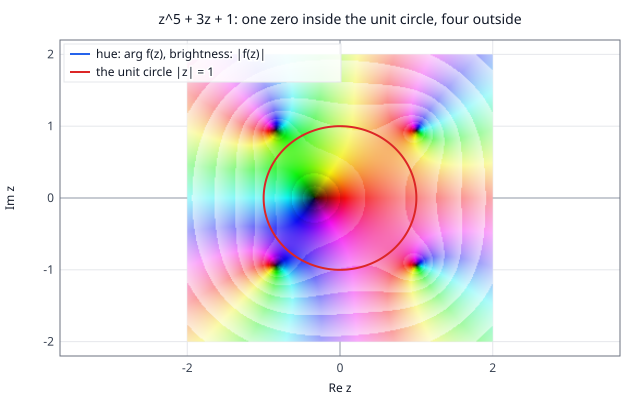

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = cplot(z^5 + 3*z + 1, z, -2, 2, -2, 2);
p = show(p, parametric(cos(t), sin(t), t, 0, 2*pi));
p = legend(p, "hue: arg f(z), brightness: |f(z)|", "the unit circle |z| = 1");
labels(title(p, "z^5 + 3z + 1: one zero inside the unit circle, four outside"), "Re z", "Im z")

And the roots themselves, for comparison:

In [6]:
eval(solve(z^5 + 3*z + 1, z))

[-0.3319890295845093, -0.8390724330666076-0.9438515501328623*i, -0.8390724330666076+0.9438515501328621*i, 1.0050669478588623-0.9372591566928918*i, 1.0050669478588623+0.9372591566928918*i]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Only $-0.332$ has modulus less than 1. A quick way to see it without integrating is **Rouché's theorem**: on $|z| = 1$,
$|3z| = 3 > |z^5 + 1|$, so $z^5 + 3z + 1$ has as many zeros inside as $3z$ does, namely one.

**Try this.** How many zeros does $z^4 - 6z + 3$ have inside $|z| = 1$? Inside $|z| = 2$? Use Rouché with $-6z$ and
then $z^4$ as the large term, and check with `cint`.

## 4. Summing series with residues

$\pi\cot(\pi z)$ has a simple pole with residue 1 at every integer $k$ (because $\sin \pi z$ has simple zeros there, and
$g/h' = \pi\cos\pi k/(\pi\cos\pi k) = 1$). So $f(z) = \pi\cot(\pi z)/z^2$ has residue $1/k^2$ at each $k \ne 0$, and at 0
a triple pole:

In [7]:
residue(pi*cot(pi*z)/z^2, z, 0)
residue(pi*cot(pi*z)/z^2, z, 3)

-pi^2/3

> Residue of f at z = 0: a pole of order 3: the residue is the coefficient of 1/(z − a) in the Laurent series, equivalently the derivative of order 2 of (z − a)^3 f at a, divided by 2!.

1/9

> Residue of f at z = 3: a simple pole: the residue is the limit of (z − a) f as z → a.

Integrate $f$ around the square with corners $(\pm(N + \tfrac12), \pm(N + \tfrac12))$. On it $\cot\pi z$ stays bounded,
so the integral is at most a constant times $(\text{length})/N^2 \sim 1/N$, which tends to 0. By the residue theorem the
sum of all residues is therefore 0:

$$-\frac{\pi^2}{3} + 2\sum_{k=1}^\infty \frac{1}{k^2} = 0, \qquad \sum_{k=1}^\infty \frac{1}{k^2} = \frac{\pi^2}{6}.$$

In [8]:
sum(1/k^2, k, 1, inf)

pi^2/6

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

The same trick with $\pi\cot(\pi z)/z^4$ gives $\sum 1/k^4 = \pi^4/90$, and with $\pi/\sin(\pi z)$ in place of
$\pi\cot(\pi z)$ it gives alternating sums.

**Try this.** Compute `residue(pi*cot(pi*z)/z^4, z, 0)` and deduce $\sum 1/k^4$.

## Summary

* **Residue theorem:** $\oint_\gamma f\,dz = 2\pi i\sum\operatorname{Res}(f, a_k)$ over the singularities inside.
* At a simple pole of $g/h$ the residue is $g(a)/h'(a)$; at a pole of order $m$, $\frac{1}{(m-1)!}$ times the
  $(m - 1)$-th derivative of $(z - a)^m f$ at $a$. `residue` and `poles` compute them.
* **Argument principle:** $\frac{1}{2\pi i}\oint f'/f\,dz$ = zeros minus poles inside; Rouché's theorem compares counts.
* Residues sum series: $\pi\cot(\pi z)$ has residue 1 at every integer, which gives $\sum 1/k^2 = \pi^2/6$.

Next: [real integrals](07-real-integrals.ipynb) computed with residues.

## Exercises

1. **Two poles.** Evaluate $\oint \dfrac{z\,dz}{(z - 1)(z - 3)}$ around $|z| = 2$ and around $|z| = 4$.
2. **Order 2.** Find the residue of $e^{2z}/(z - 1)^2$ at 1 by the formula, and check with `residue`.
3. **Zeros and poles.** For $f = (z^2 - 1)/(z^2 + 4)$, compute $\frac{1}{2\pi i}\oint f'/f\,dz$ around $|z| = 3$ and around
   $|z| = 1.5$, and explain both answers.
4. **Rouché.** Show that all five zeros of $z^5 + 3z + 1$ lie in $|z| < 2$ using Rouché with $z^5$ as the large term.
5. **Alternating sum.** Use $\pi/(z^2\sin \pi z)$, whose residue at $k \ne 0$ is $(-1)^k/k^2$, to show
   $1 - \tfrac14 + \tfrac19 - \cdots = \pi^2/12$.

## Hints and answers

* **Section 1, Try this.** Only the pole at $i$: $2\pi i \cdot e^i/(2i) = \pi e^i$, about $1.697 + 2.644i$.
* **Section 2, Try this.** $(z - 1)^3 f = z$, whose second derivative is 0: residue 0.
* **Section 3, Try this.** On $|z| = 1$, $|-6z| = 6 > |z^4 + 3| \le 4$: one zero. On $|z| = 2$, $|z^4| = 16 > |-6z + 3|
  \le 15$: four zeros. So three lie in $1 < |z| < 2$.
* **Section 4, Try this.** The residue is $-\pi^4/45$, so $2\sum 1/k^4 = \pi^4/45$ and $\sum 1/k^4 = \pi^4/90$.
* **Exercise 1.** Residues $-1/2$ at 1 and $3/2$ at 3: $-\pi i$ around $|z| = 2$, $2\pi i$ around $|z| = 4$.
* **Exercise 2.** $\frac{d}{dz}e^{2z} = 2e^{2z}$ at 1: $2e^2$.
* **Exercise 3.** Around $|z| = 3$: 2 zeros, 2 poles, so 0. Around $|z| = 1.5$: 2 zeros, no poles, so 2.
* **Exercise 4.** On $|z| = 2$, $|z^5| = 32 > |3z + 1| \le 7$.
* **Exercise 5.** The residue at 0 is $\pi^2/6$; the sum of all residues is 0, so $\pi^2/6 + 2\sum(-1)^k/k^2 = 0$.

## Sources

1. A. L. Cauchy, *Exercices de mathématiques* (1826), where the calculus of residues is introduced.
2. E. Rouché, *Journal de l'École Polytechnique* 39 (1862) 193–224.
3. E. M. Stein and R. Shakarchi, *Complex Analysis*, Princeton University Press (2003), chapter 3.
4. J. W. Brown and R. V. Churchill, *Complex Variables and Applications*, 9th ed., McGraw-Hill (2014), chapters 6 and 7.